# 04 · Fault injection and fault signatures

**Goal.** Inject seven realistic faults into the simulator, label them, and measure each fault's **signature**: how far, in units of normal noise, every KPI stream moves. Then answer the question left open by notebooks 02 and 03: **which real faults break the normal coupling between slices**, and so should be caught faster by a coupled detector?

Faults are `Fault` objects (`src/slicead/sim/config.py`). Each multiplies one model parameter (the server capacity, or a slice's traffic rate, radio loss or scheduling weight) from a change time on, as a step or a linear ramp. The scenarios are in `configs/faults.yaml`; tests are in `tests/test_faults.py`.

**Run it** from the project root (about 3 minutes):

```
.venv\Scripts\python -m nbconvert --to notebook --execute --inplace notebooks/04_fault_signatures.ipynb
```

**Sections:** 1 Setup · 2 The fault scenarios · 3 Simulation · 4 What a fault looks like · 5 Signatures · 6 Do faults break the coupling? · 7 Summary

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from slicead.sim import load_config, load_fault_scenarios, simulate, KPI_NAMES

SEED = 20261022
OUT = Path("../results/04_fault_signatures")
OUT.mkdir(parents=True, exist_ok=True)
REPORT = Path("../report")
for sub in ("figures", "tables"):                      # report/ is not in the public repository
    (REPORT / sub).mkdir(parents=True, exist_ok=True)
(REPORT / "figures").mkdir(parents=True, exist_ok=True)
(REPORT / "tables").mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight")
    fig.savefig(REPORT / "figures" / f"04_{name}.pdf", bbox_inches="tight")

def save_tex_table(df, name, column_format):
    # tabular only; caption and label live in report/main.tex
    (REPORT / "tables" / f"04_{name}.tex").write_text(
        df.to_latex(index=False, escape=False, column_format=column_format), encoding="utf-8")

def save_tex_numbers(numbers, name="numbers"):
    lines = [f"\\newcommand{{\\{k}}}{{{v}}}" for k, v in numbers.items()]
    (REPORT / "tables" / f"04_{name}.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
SLICE_COLORS = [BLUE, ORANGE, AQUA]
DIVERGING = LinearSegmentedColormap.from_list("div", ["#184f95", "#86b6ef", "#f0efec", "#f19c9b", "#b8302f"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "lines.markersize": 7, "font.size": 10,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 150,
})

cfg = load_config("../configs/sim_default.yaml")
CHANGE_S = 60.0                                     # fault starts 60 s after warm-up
SCENARIOS = load_fault_scenarios("../configs/faults.yaml", start_s=CHANGE_S)
print(list(SCENARIOS))

['capacity_drop', 'capacity_degradation', 'embb_surge', 'urllc_surge', 'mmtc_storm', 'urllc_loss_burst', 'urllc_weight_misconfig']


## 2. The fault scenarios

| scenario | what changes | expected effect |
|---|---|---|
| capacity drop | server capacity × 0.7 (e.g. a carrier fails) | **shared**: every slice slows down |
| capacity degradation | the same 30% loss, as a linear ramp over 60 s | **shared**, and gradual |
| eMBB surge | eMBB traffic × 1.3 | **shared**: a busier server for everyone |
| URLLC surge | URLLC traffic × 5 (2 → 10 Mbit/s), still inside its share | **local** to URLLC |
| mMTC storm | mMTC traffic × 3 (8 → 24 Mbit/s), above its 20 Mbit/s share | **competitive**: mMTC takes capacity from eMBB |
| URLLC loss burst | URLLC radio loss $10^{-5} \to 10^{-2}$ | **local**, loss only |
| URLLC weight misconfiguration | URLLC weight × 0.1 (0.30 → 0.04); the others gain | **competitive**: URLLC slows, the others may speed up |

The "expected effect" column is a hypothesis; section 6 checks it. Magnitudes are illustrative assumptions, chosen to be clearly visible but not catastrophic.

In [2]:
NICE = {"capacity_drop": "capacity drop", "capacity_degradation": "capacity degradation",
        "embb_surge": "eMBB surge", "urllc_surge": "URLLC surge", "mmtc_storm": "mMTC storm",
        "urllc_loss_burst": "URLLC loss burst", "urllc_weight_misconfig": "URLLC weight misconfig."}
EXPECTED = {"capacity_drop": "shared", "capacity_degradation": "shared", "embb_surge": "shared",
            "urllc_surge": "local", "mmtc_storm": "competitive", "urllc_loss_burst": "local",
            "urllc_weight_misconfig": "competitive"}

def describe(f):
    target = "capacity" if f.kind == "capacity" else f"{f.slice} {f.kind.replace('_', ' ')}"
    how = f"linear over {f.ramp_s:g} s" if f.ramp_s else "step"
    return f"{target} $\\times$ {f.factor:g} ({how})"

tab = pd.DataFrame([dict(scenario=NICE[n], change="; ".join(describe(f) for f in fs), expected=EXPECTED[n])
                    for n, fs in SCENARIOS.items()])
save_tex_table(tab, "scenarios", "lll")
tab

,scenario,change,expected
0,capacity drop,capacity $\times$ 0.7 (step),shared
1,capacity degradation,capacity $\times$ 0.7 (linear over 60 s),shared
2,eMBB surge,eMBB traffic $\times$ 1.3 (step),shared
3,URLLC surge,URLLC traffic $\times$ 5 (step),local
4,mMTC storm,mMTC traffic $\times$ 3 (step),competitive
5,URLLC loss burst,URLLC radio loss $\times$ 1000 (step),local
6,URLLC weight misconfig.,URLLC weight $\times$ 0.1 (step),competitive


## 3. Simulation

Each scenario gets 8 independent runs of 3 minutes (1,800 windows). The fault starts at 60 s, so every run has 600 fault-free windows to learn "normal" from, then 1,200 faulty ones. All runs and scenarios share the same seed, so differences between scenarios are not just noise.

In [3]:
N_RUNS, N_WINDOWS = 8, 1800
results = {name: simulate(cfg, n_windows=N_WINDOWS, n_runs=N_RUNS, seed=SEED, faults=faults)
           for name, faults in SCENARIOS.items()}
r0 = results["capacity_drop"]
names = r0.slice_names
print(f"fault window index {r0.fault_window}, labelled windows per run {int(r0.labels.sum())} of {N_WINDOWS}")

fault window index 600, labelled windows per run 1200 of 1800


## 4. What a fault looks like

Latency of each slice in four scenarios, as a z-score against its own fault-free mean and standard deviation. To make the shift visible through the noise, each curve is averaged over the 8 runs and smoothed over 1 s. A detector sees one noisy run, not this average.

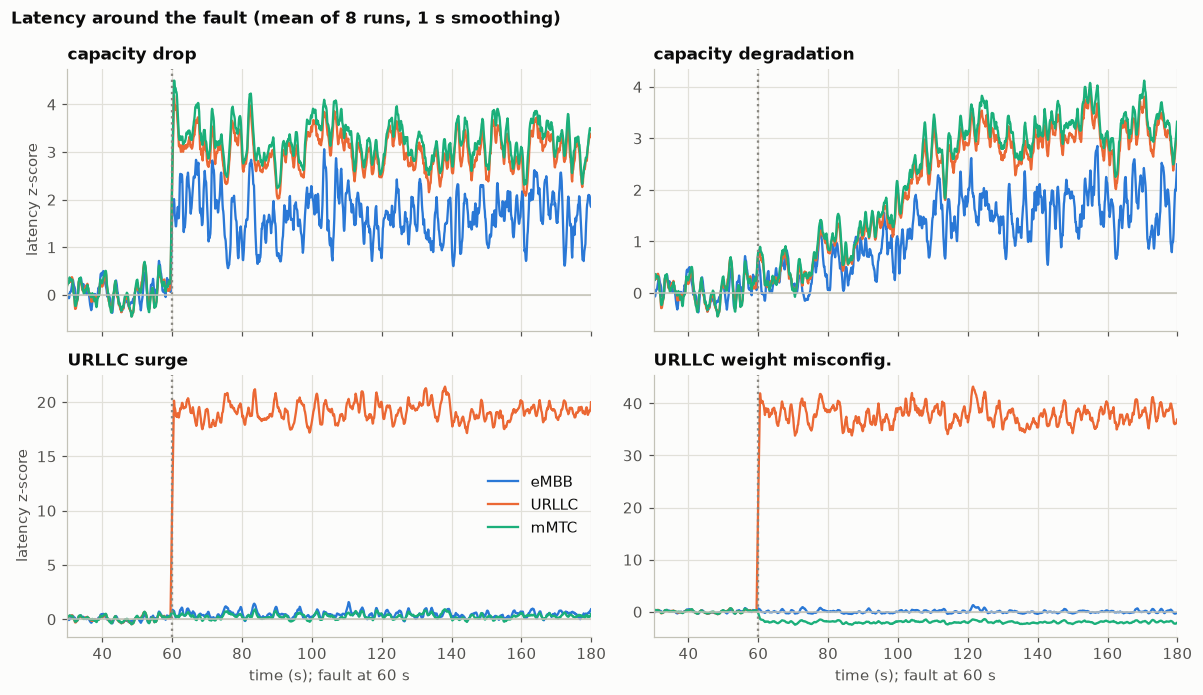

In [4]:
SHORT = {"throughput_mbps": "thr", "latency_ms": "lat", "jitter_ms": "jit", "loss_pct": "loss"}
STREAMS = [(s, k) for s in range(len(names)) for k in KPI_NAMES]
LABELS = [f"{names[s]} {SHORT[k]}" for s, k in STREAMS]
LAT = [i for i, (s, k) in enumerate(STREAMS) if k == "latency_ms"]

def stream_matrix(res, run):
    X = np.column_stack([res.kpi(k)[run, :, s] for s, k in STREAMS])
    return pd.DataFrame(X).ffill().bfill().to_numpy()

def masks(res, post_from_s):
    pre = ~res.labels
    post = res.time_s >= post_from_s - 1e-9
    return pre, post

def post_start(name):
    # skip 2 s of transient; for a ramp, wait until the ramp is complete
    ramp = max(f.ramp_s for f in SCENARIOS[name])
    return CHANGE_S + ramp + 2.0


def z_traces(res):
    pre, _ = masks(res, CHANGE_S)
    Z = []
    for r in range(res.kpis.shape[0]):
        X = stream_matrix(res, r)
        with np.errstate(invalid="ignore", divide="ignore"):
            Z.append((X - X[pre].mean(axis=0)) / X[pre].std(axis=0))
    return np.mean(Z, axis=0)

show = ["capacity_drop", "capacity_degradation", "urllc_surge", "urllc_weight_misconfig"]
fig, axes = plt.subplots(2, 2, figsize=(11, 6.4), sharex=True)
for ax, name in zip(axes.ravel(), show):
    res = results[name]
    Z = pd.DataFrame(z_traces(res)).rolling(10, center=True, min_periods=1).mean().to_numpy()
    for s, col in zip(range(len(names)), SLICE_COLORS):
        ax.plot(res.time_s, Z[:, LAT[s]], color=col, lw=1.5, label=names[s])
    ax.axvline(CHANGE_S, color=MUTED, ls=":", lw=1.5)
    ax.axhline(0, color=AXIS, lw=1)
    ax.set_title(NICE[name])
    ax.set_xlim(30, 180)
axes[1, 0].legend(loc="center right")
for ax in axes[:, 0]:
    ax.set_ylabel("latency z-score")
for ax in axes[1]:
    ax.set_xlabel("time (s); fault at 60 s")
fig.suptitle("Latency around the fault (mean of 8 runs, 1 s smoothing)", x=0.01, ha="left", fontsize=11,
             fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig1_fault_traces")
plt.show()

## 5. Signatures

For every scenario and KPI stream we measure the post-fault shift in units of the fault-free standard deviation:

$$\delta_j = \frac{\text{mean after the fault} - \text{mean before}}{\text{standard deviation before}},$$

averaged over the 8 runs. "After" starts 2 s after the change (60 s after it, plus 2 s, for the ramp), to skip the transient.

We compute it twice. **Raw** uses the window KPIs themselves. **Whitened** uses the residuals of each stream's own AR(1) prediction-error filter, fitted on the fault-free part, which is what a CUSUM on whitened residuals sees. Whitening shrinks a step shift by a factor of about $\sqrt{(1-\phi)/(1+\phi)}$, because a slow change looks predictable to the filter. That is the price of removing the noise's memory. The standard deviation is pooled over runs, so streams that are almost always zero (URLLC loss) do not divide by zero in a single run.

In [5]:
def signature(res, post_from_s):
    pre, post = masks(res, post_from_s)
    Xs = [stream_matrix(res, r) for r in range(res.kpis.shape[0])]
    sd_pre = np.concatenate([X[pre] for X in Xs]).std(axis=0)
    raw = np.mean([(X[post].mean(axis=0) - X[pre].mean(axis=0)) / sd_pre for X in Xs], axis=0)
    sd_ratio = np.mean([X[post].std(axis=0) for X in Xs], axis=0) / sd_pre
    E_all, phis = [], []
    for X in Xs:
        Xc = X - X[pre].mean(axis=0)
        P = Xc[pre]
        phi = np.divide((P[1:] * P[:-1]).sum(axis=0), (P**2).sum(axis=0), out=np.zeros(P.shape[1]),
                        where=(P**2).sum(axis=0) > 0)
        E_all.append(Xc[1:] - phi * Xc[:-1])
        phis.append(phi)
    pre1, post1 = pre[1:], post[1:]
    sd_e = np.concatenate([E[pre1] for E in E_all]).std(axis=0)
    white = np.mean([(E[post1].mean(axis=0) - E[pre1].mean(axis=0)) / sd_e for E in E_all], axis=0)
    corr_white = np.mean([np.corrcoef(E[pre1].T) for E in E_all], axis=0)
    return dict(raw=raw, white=white, sd_ratio=sd_ratio, corr_white=corr_white, phi=np.mean(phis, axis=0))

with np.errstate(invalid="ignore", divide="ignore"):
    sigs = {name: signature(res, post_start(name)) for name, res in results.items()}

order = list(SCENARIOS)
raw = pd.DataFrame([sigs[n]["raw"] for n in order], index=[NICE[n] for n in order], columns=LABELS)
white = pd.DataFrame([sigs[n]["white"] for n in order], index=[NICE[n] for n in order], columns=LABELS)
raw.to_csv(OUT / "signatures_raw.csv"); white.to_csv(OUT / "signatures_whitened.csv")
print("Whitened signatures (shift in fault-free standard deviations):")
white.round(2)

Whitened signatures (shift in fault-free standard deviations):


,eMBB thr,eMBB lat,eMBB jit,eMBB loss,URLLC thr,URLLC lat,URLLC jit,URLLC loss,mMTC thr,mMTC lat,mMTC jit,mMTC loss
capacity drop,-0.09,0.63,1.00,1.41,-0.01,1.48,1.82,-0.00,-0.01,1.32,1.02,-0.03
capacity degradation,-0.10,0.61,0.96,1.39,-0.01,1.48,1.86,0.00,-0.00,1.32,1.05,-0.03
eMBB surge,0.10,0.31,0.51,1.01,0.00,0.13,0.02,0.00,-0.00,0.12,-0.12,-0.02
URLLC surge,-0.00,0.18,0.28,0.22,63.03,9.37,6.87,0.00,-0.03,0.11,-0.13,-0.02
mMTC storm,-0.03,0.34,0.52,0.60,-0.03,0.02,-0.04,-0.00,92.02,12.65,7.28,0.36
URLLC loss burst,0.01,0.03,0.02,0.04,-0.17,0.02,0.01,50.46,-0.02,0.02,-0.01,-0.01
URLLC weight misconfig.,0.01,0.01,0.01,0.01,-0.02,18.50,24.70,0.01,-0.02,-0.80,-0.51,-0.03


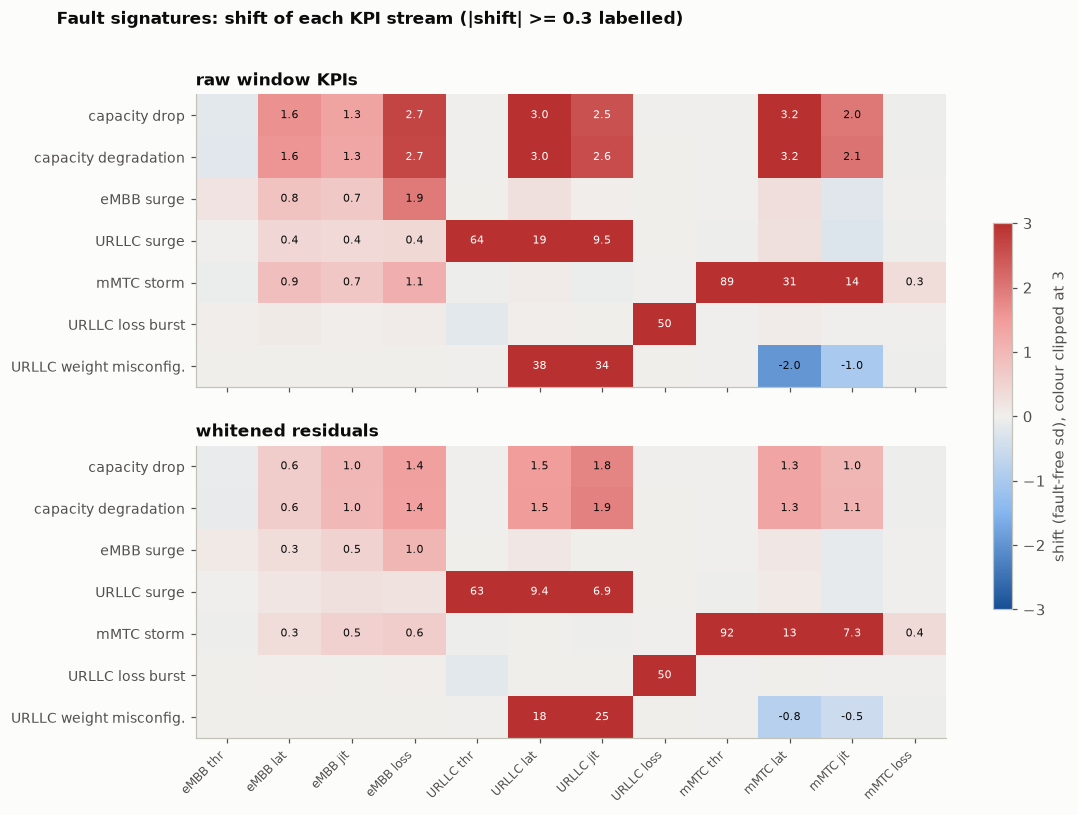

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7.6))
for ax, D, title in [(axes[0], raw, "raw window KPIs"), (axes[1], white, "whitened residuals")]:
    V = D.to_numpy()
    im = ax.imshow(np.clip(V, -3, 3), cmap=DIVERGING, vmin=-3, vmax=3, aspect="auto")
    ax.set_xticks(range(len(LABELS)), LABELS if ax is axes[1] else [], rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(order)), D.index, fontsize=9)
    ax.grid(False)
    for i in range(V.shape[0]):
        for j in range(V.shape[1]):
            if abs(V[i, j]) >= 0.3:
                txt = f"{V[i, j]:.0f}" if abs(V[i, j]) >= 10 else f"{V[i, j]:.1f}"
                ax.text(j, i, txt, ha="center", va="center", fontsize=7,
                        color="white" if abs(V[i, j]) > 2.2 else INK)
    ax.set_title(title)
fig.colorbar(im, ax=axes, shrink=0.6, label="shift (fault-free sd), colour clipped at 3")
fig.suptitle("Fault signatures: shift of each KPI stream (|shift| >= 0.3 labelled)", x=0.01, ha="left",
             fontsize=11, fontweight="bold")
save_fig(fig, "fig2_signatures")
plt.show()

**What the signatures show**

- **Each fault has a clear fingerprint.**
  - Traffic surges and the mMTC storm show up first in the slice's own *throughput* (64–89 sd raw). Below its guaranteed share a slice delivers what arrives, so a surge is directly visible as delivered rate.
  - The loss burst moves only URLLC loss (50 sd). No other KPI notices it.
  - The capacity drop and degradation move the latency and jitter of *every* slice, plus eMBB loss, by a moderate amount: 1.3–3.2 sd raw, 0.6–1.9 sd whitened.
  - The weight misconfiguration sends URLLC latency and jitter up enormously (38 and 34 sd raw), while mMTC latency goes *down* (−2.0 sd raw): mMTC inherits part of URLLC's lost weight.
  - The eMBB surge is the subtlest fault: eMBB latency moves +0.8 sd raw and +0.3 sd whitened.
- **Whitening shrinks every shift by the amount theory predicts.** For a step, the AR(1) residual shift is the raw shift times $\sqrt{(1-\phi)/(1+\phi)}$. For example, URLLC latency under the capacity drop goes from 2.99 to 1.48 sd, where $\phi \approx 0.62$ predicts 1.45. Whitening buys calibrated false alarms at the price of a smaller apparent shift.
- **"50 sd" on URLLC loss is a statement about a near-constant stream.** URLLC loss is count-like and almost always zero. Such KPIs need count models (a Poisson or binomial CUSUM), not Gaussian ones.

## 6. Do faults break the coupling?

Notebook 03 found that latency is the coupled KPI, so we ask the question there. For each fault, let $\delta$ be its whitened latency signature for the three slices and $\Sigma$ the fault-free correlation of the whitened latency residuals. The first-order information of a coupled detector that knows $\delta$, relative to the best single-slice latency detector, is

$$\text{gain} = \frac{\tfrac12\,\delta^\top\Sigma^{-1}\delta}{\max_j \tfrac12\,\delta_j^2} \;\ge\; 1.$$

Notebooks 01 and 02 showed that the realised speed-up at a practical ARL is smaller than this ratio, so treat it as an upper guide.

**Shape** labels the sign pattern of $\delta$. A slice counts as having moved if its shift is at least 0.2 sd and at least 10% of the largest shift. The shape is *shared* when all the slices that moved go the same way, *competitive* when they go opposite ways, *local* when only one moved, and *none* when latency does not move at all.

In [7]:
def shape_of(d, floor=0.2, rel=0.1):
    # a slice 'moved' if its shift is at least 0.2 sd and at least 10% of the largest shift
    big = np.abs(d).max()
    if big < floor:
        return "none"
    moved = np.abs(d) >= max(floor, rel * big)
    if moved.sum() <= 1:
        return "local"
    return "shared" if len(set(np.sign(d[moved]))) == 1 else "competitive"

rows = []
for n in order:
    d = sigs[n]["white"][LAT]
    S = sigs[n]["corr_white"][np.ix_(LAT, LAT)]
    kl_c = 0.5 * d @ np.linalg.solve(S, d)
    best = int(np.argmax(np.abs(d)))
    kl_s = 0.5 * d[best] ** 2
    rows.append(dict(scenario=NICE[n], expected=EXPECTED[n], measured_shape=shape_of(d),
                     **{f"d_{names[s]}": d[s] for s in range(len(names))},
                     best_single=names[best], KL_single=kl_s, KL_coupled=kl_c,
                     gain=kl_c / kl_s if shape_of(d) != "none" else np.nan))   # no gain without a shift
coupling = pd.DataFrame(rows)
coupling.to_csv(OUT / "latency_coupling_gain.csv", index=False)
Sigma_lat = np.mean([sigs[n]["corr_white"][np.ix_(LAT, LAT)] for n in order], axis=0)
print("fault-free whitened latency correlation (mean over scenarios):\n", np.round(Sigma_lat, 2))
coupling.round(3)

fault-free whitened latency correlation (mean over scenarios):
 [[1.   0.42 0.5 ]
 [0.42 1.   0.72]
 [0.5  0.72 1.  ]]


,scenario,expected,measured_shape,d_eMBB,d_URLLC,d_mMTC,best_single,KL_single,KL_coupled,gain
0,capacity drop,shared,shared,0.630,1.476,1.317,URLLC,1.089,1.165,1.070
1,capacity degradation,shared,shared,0.610,1.484,1.322,URLLC,1.101,1.180,1.071
2,eMBB surge,shared,local,0.312,0.128,0.120,eMBB,0.049,0.050,1.028
3,URLLC surge,local,local,0.175,9.370,0.113,URLLC,43.899,89.015,2.028
4,mMTC storm,competitive,local,0.339,0.022,12.646,mMTC,79.964,179.253,2.242
5,URLLC loss burst,local,none,0.033,0.021,0.023,eMBB,0.001,0.001,NaN
6,URLLC weight misconfig.,competitive,local,0.013,18.496,-0.804,URLLC,171.051,375.004,2.192


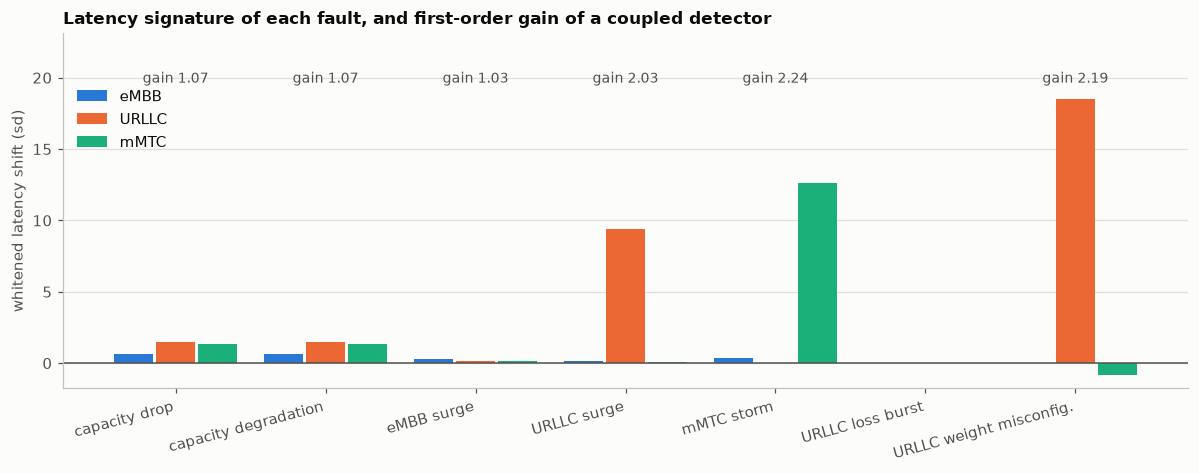

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.4))
x = np.arange(len(order))
w = 0.26
for s, col in zip(range(len(names)), SLICE_COLORS):
    ax.bar(x + (s - 1) * (w + 0.02), coupling[f"d_{names[s]}"], width=w, color=col, label=names[s])
ax.axhline(0, color=INK2, lw=1)
ax.set_xticks(x, coupling.scenario, rotation=15, ha="right")
ax.grid(axis="x", visible=False)
ymax = np.nanmax(np.abs(coupling[[f"d_{n}" for n in names]].to_numpy()))
for i, g in enumerate(coupling.gain):
    if np.isfinite(g):
        ax.annotate(f"gain {g:.2f}", (i, ymax * 1.05), ha="center", va="bottom", color=INK2, fontsize=9)
ax.set_ylim(top=ymax * 1.25)
ax.set_ylabel("whitened latency shift (sd)")
ax.set_title("Latency signature of each fault, and first-order gain of a coupled detector")
ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.88))
fig.tight_layout()
save_fig(fig, "fig3_latency_shapes")
plt.show()

**What it shows**

- **The hypothesis holds for shared and local faults.** Capacity faults are shared: all three latencies rise, and a coupled detector gains almost nothing (first-order gain 1.07). The eMBB surge was expected to be shared too, but its spill-over into URLLC and mMTC latency (0.13 and 0.12 whitened sd) falls below the 0.2 sd floor, so it measures as local to eMBB; its gain is 1.03. The URLLC surge is local, and its gain of 2.03 is close to $1/(1-\rho^2) = 2.08$ for URLLC's most correlated partner, mMTC ($\rho = 0.72$).
- **"Competitive" faults do not look competitive in latency.** The mMTC storm takes capacity from eMBB, yet both slices get *slower*, because the slice that takes capacity also queues. In latency the storm is local to mMTC (12.6 sd, against 0.3 for eMBB). Only the weight misconfiguration produces an opposite move (mMTC −0.8 sd while URLLC +18.5), and that move is small next to the main shift. The gains for the storm and the misconfiguration are 2.24 and 2.19.
- **The gain appears where it is least needed.**
  - The faults confined to one slice are large here (9–18 whitened sd), so a detector on that slice catches them within a window or two. A twofold information gain hardly changes that delay.
  - The subtle faults (capacity drop, 0.6–1.5 sd; eMBB surge, 0.1–0.3 sd) are shared, and for them coupling adds 3–7%.
  - With these fault sizes, the coupled detector's advantage is real but mostly irrelevant. Its value, if any, will be for *small* slice-local faults, so task 6 should sweep fault magnitude rather than use one size per fault.

In [9]:
# Export tables and key numbers for report/main.tex
f2 = lambda v: f"{v:+.2f}"
tab = coupling.assign(**{f"d_{n}": coupling[f"d_{n}"].map(f2) for n in names},
                      KL_single=coupling.KL_single.map("{:.3f}".format),
                      KL_coupled=coupling.KL_coupled.map("{:.3f}".format),
                      gain=coupling.gain.map(lambda g: "--" if not np.isfinite(g) else f"{g:.2f}"))
tab = tab[["scenario", "expected", "measured_shape"] + [f"d_{n}" for n in names] + ["KL_single", "KL_coupled", "gain"]]
tab.columns = ["scenario", "expected", "measured", *[f"$\\delta$ {n}" for n in names], "KL single", "KL coupled", "gain"]
save_tex_table(tab, "latency_gain", "lllrrrrrr")

C = coupling.set_index("scenario")
g = lambda n: C.loc[NICE[n], "gain"]
d = lambda n, s: C.loc[NICE[n], f"d_{s}"]
save_tex_numbers({
    "FaultChangeS": f"{CHANGE_S:g}",
    "GainCapDrop": f"{g('capacity_drop'):.2f}",
    "GainUrllcSurge": f"{g('urllc_surge'):.2f}",
    "GainMisconfig": f"{g('urllc_weight_misconfig'):.2f}",
    "GainStorm": f"{g('mmtc_storm'):.2f}",
    "GainMax": f"{np.nanmax(coupling.gain):.2f}",
    "DCapDropEmbb": f"{d('capacity_drop', 'eMBB'):.2f}",
    "DCapDropUrllc": f"{d('capacity_drop', 'URLLC'):.2f}",
    "DMisconfigUrllc": f"{d('urllc_weight_misconfig', 'URLLC'):.2f}",
    "DMisconfigEmbb": f"{d('urllc_weight_misconfig', 'eMBB'):.2f}",
})
print("exported:", sorted(p.name for p in (REPORT / "tables").glob("04_*")))

exported: ['04_latency_gain.tex', '04_numbers.tex', '04_scenarios.tex']


## 7. Summary

- **Faults are in the simulator.** They are injected as parameter changes (a step or a ramp), labelled per window, and tested; a no-op fault reproduces the fault-free output bit for bit.
- **Each fault has a distinct fingerprint.**
  - Surges show in the slice's own throughput.
  - The loss burst shows only in URLLC loss.
  - Capacity faults show moderately in every slice's latency and jitter.
  - The weight misconfiguration shows hugely in URLLC latency, with a small opposite move in mMTC.
- **Whitening shrinks shifts by $\sqrt{(1-\phi)/(1+\phi)}$** (about 0.5 for latency), as theory predicts.
- **First-order coupled-detector gain in latency** is about 1.0–1.07 for shared faults and about 2.0–2.2 for faults concentrated in one slice, the latter close to $1/(1-\rho^2)$.
- **Coupling helps where faults are already large.** The subtle faults here are shared. The evaluation must therefore sweep fault magnitude, and the strongest case for coupling would be small slice-local faults.
- **Next (task 6):** baseline and per-slice CUSUM detectors on whitened residuals, calibrated to a common simulated ARL, with conditional delay for each fault and magnitude.